# Day 1 · 이론 3 추가 실습 — 선형 회귀와 다항 회귀

* [실습 -A] : 회귀식 직접 계산과 세 모델의 예측 비교 
* [실습 -B] : 잔차 분석으로 모델의 오차 패턴 이해하기 

## 0. 공통 준비 — 교재와 같은 농어 데이터 및 훈련·테스트 분할

이론 ③의 농어 56마리, `random_state=42`, 훈련 42마리·테스트 14마리를 그대로 사용합니다. 변수 이름은 교재와 구별할 수 있도록 모델에 `_compare`, `_linear`, `_poly`를 붙입니다.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

perch_length = np.array([
    8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0,
])

perch_weight = np.array([
    5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0,
])

train_input, test_input, train_target, test_target = train_test_split(
    perch_length, perch_weight, random_state=42
)
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)

# 이론 ③과 동일한 [길이², 길이] 특성
train_poly_extra = np.column_stack((train_input ** 2, train_input))
test_poly_extra = np.column_stack((test_input ** 2, test_input))

print('훈련 입력:', train_input.shape, '| 테스트 입력:', test_input.shape)
print(f'훈련 데이터의 길이 범위: {train_input.min():.1f}~{train_input.max():.1f}cm')

훈련 입력: (42, 1) | 테스트 입력: (14, 1)
훈련 데이터의 길이 범위: 13.7~44.0cm


가장 작은 농어(8.4cm)는 테스트 세트에 들어가 있어서, 훈련 데이터의 길이 범위는 13.7~44.0cm입니다.

## [실습 -A] 회귀식 직접 계산과 세 모델의 예측 비교

**실습 목표**

1. 선형·다항 회귀의 학습된 계수와 절편으로 예측값을 직접 계산하고 `predict()`와 비교합니다.
2. KNN은 가까운 이웃의 평균, 선형 회귀는 직선식, 다항 회귀는 2차식으로 예측한다는 차이를 확인합니다.
3. 훈련 길이 **범위 안(30, 40cm)**과 **범위 밖(50, 60cm)**에서 예측이 어떻게 달라지는지 관찰합니다.

### 1단계. 동일한 데이터로 세 모델 훈련하기

각 모델을 별도 변수로 보관합니다. 이론 ③에서 선형 회귀용 `lr`을 다항 회귀에 다시 사용했으므로, 이 추가 실습에서는 실수로 모델을 덮어쓰지 않도록 이름을 구분합니다.

KNN 회귀의 이웃 수는 이론 ③의 설정과 같이 3입니다. 실습 ②-A에서는 이웃 5마리를 사용했으므로, 같은 30cm 농어라도 두 실습의 KNN 예측값은 다릅니다.

In [12]:
knr_compare = KNeighborsRegressor(n_neighbors=3)
knr_compare.fit(train_input, train_target)

lr_linear = LinearRegression()
lr_linear.fit(train_input, train_target)

lr_poly = LinearRegression()
lr_poly.fit(train_poly_extra, train_target)

print('직선 회귀 계수:', lr_linear.coef_[0])
print('직선 회귀 절편:', lr_linear.intercept_)
print('2차 다항 회귀 계수:', lr_poly.coef_)
print('2차 다항 회귀 절편:', lr_poly.intercept_)

직선 회귀 계수: 39.017144963630194
직선 회귀 절편: -709.0186449535477
2차 다항 회귀 계수: [  1.01433211 -21.55792498]
2차 다항 회귀 절편: 116.05021078278247


### 2단계. 40cm 농어의 무게를 회귀식으로 직접 계산하기

직선 회귀는 `a × 길이 + b`, 2차 다항 회귀는 `a × 길이² + b × 길이 + c`를 계산합니다. 계수와 절편은 코드에 임의로 적지 않고, 훈련된 모델의 속성에서 가져옵니다.

In [13]:
length = 40.0

linear_manual = lr_linear.coef_[0] * length + lr_linear.intercept_
linear_predict = lr_linear.predict([[length]])[0]

poly_manual = (
    lr_poly.coef_[0] * length ** 2
    + lr_poly.coef_[1] * length
    + lr_poly.intercept_
)
poly_predict = lr_poly.predict([[length ** 2, length]])[0]

print(f'직선 회귀: 직접 계산 {linear_manual:.2f}g / predict() {linear_predict:.2f}g')
print(f'다항 회귀: 직접 계산 {poly_manual:.2f}g / predict() {poly_predict:.2f}g')

assert np.isclose(linear_manual, linear_predict)
assert np.isclose(poly_manual, poly_predict)

직선 회귀: 직접 계산 851.67g / predict() 851.67g
다항 회귀: 직접 계산 876.66g / predict() 876.66g


실습 -A에서 이웃의 평균이 KNN의 예측값과 같았던 것처럼, 선형 회귀와 다항 회귀도 학습한 계수로 만든 식의 계산 결과가 곧 예측값입니다.

### 3단계. 30·40·50·60cm 농어를 세 모델로 예측하기

주의: 50cm와 60cm는 훈련 길이 범위를 벗어난 입력입니다. 예측값이 계산된다는 사실과 그 값이 정확하다는 사실은 다릅니다.

In [14]:
lengths_to_predict = np.array([30.0, 40.0, 50.0, 60.0]).reshape(-1, 1)
lengths_poly = np.column_stack((lengths_to_predict ** 2, lengths_to_predict))

knn_pred = knr_compare.predict(lengths_to_predict)
linear_pred = lr_linear.predict(lengths_to_predict)
poly_pred = lr_poly.predict(lengths_poly)

print('길이  |  KNN(k=3)  |  직선 회귀  |  2차 다항 회귀  |  훈련 범위')
for x, a, b, c in zip(lengths_to_predict[:, 0], knn_pred, linear_pred, poly_pred):
    position = '안' if train_input.min() <= x <= train_input.max() else '밖'
    print(f'{x:4.0f}cm | {a:10.2f}g | {b:10.2f}g | {c:12.2f}g | 범위 {position}')

길이  |  KNN(k=3)  |  직선 회귀  |  2차 다항 회귀  |  훈련 범위
  30cm |     275.00g |     461.50g |       382.21g | 범위 안
  40cm |     921.67g |     851.67g |       876.66g | 범위 안
  50cm |    1033.33g |    1241.84g |      1573.98g | 범위 밖
  60cm |    1033.33g |    1632.01g |      2474.17g | 범위 밖


50cm 행의 세 값은 이론 ③ 본문에서 확인한 1,033g·1,242g·1,574g과 같습니다. 60cm에서는 KNN은 그대로이고, 직선과 2차 곡선은 서로 다른 속도로 계속 커집니다.

### 4단계. 세 모델의 예측선 함께 그리기

훈련 길이의 최댓값(44cm)을 점선으로 표시합니다. 점선 오른쪽은 훈련 범위 밖이며, 이 영역에서는 모델마다 예측값이 크게 달라질 수 있습니다.

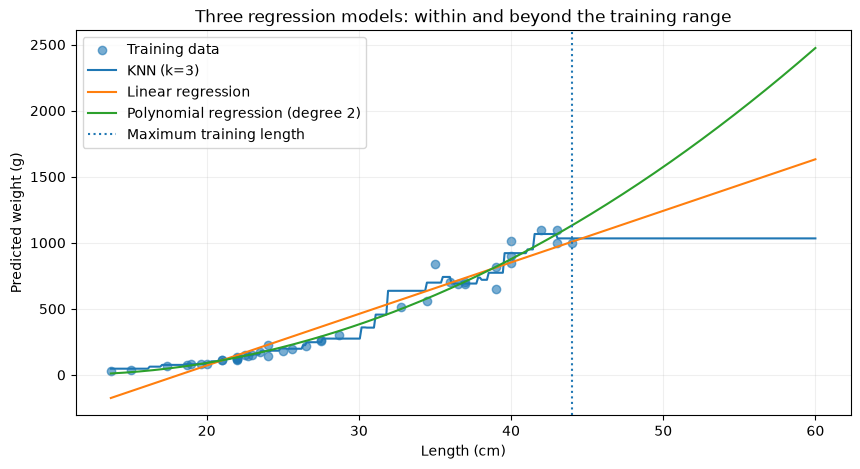

In [15]:
x_grid = np.linspace(train_input.min(), 60, 400).reshape(-1, 1)
x_grid_poly = np.column_stack((x_grid ** 2, x_grid))

plt.figure(figsize=(10, 5))
plt.scatter(train_input[:, 0], train_target, alpha=0.6, label='Training data')
plt.plot(x_grid[:, 0], knr_compare.predict(x_grid), label='KNN (k=3)')
plt.plot(x_grid[:, 0], lr_linear.predict(x_grid), label='Linear regression')
plt.plot(x_grid[:, 0], lr_poly.predict(x_grid_poly), label='Polynomial regression (degree 2)')
plt.axvline(train_input.max(), linestyle=':', label='Maximum training length')
plt.xlabel('Length (cm)')
plt.ylabel('Predicted weight (g)')
plt.title('Three regression models: within and beyond the training range')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

점선 왼쪽에서는 세 선이 훈련 데이터를 따라 비슷하게 움직이지만, 점선 오른쪽에서는 KNN은 수평, 직선은 일정한 기울기, 2차 곡선은 점점 가파르게 벌어집니다.

### 5단계. 학생 응용 실습

3단계의 `lengths_to_predict`를 `[35, 45, 55, 65]`로 변경하고 예측값을 비교해 보세요.

**실습 핵심**: KNN은 사례의 평균을 사용하지만 선형·다항 회귀는 학습한 계수로 관계식을 만듭니다. 세 모델은 학습 범위 밖에서도 값을 반환하지만, 특히 범위 밖의 값은 실제 정답 없이 정확하다고 판단할 수 없습니다.

✅ **완료 확인**: 2단계에서 직접 계산과 `predict()`가 `851.67g`·`876.66g`으로 같고, 3단계 표의 50cm 행이 이론 ③ 본문의 세 값과 일치합니다. 응용 실습(`[35, 45, 55, 65]`)에서는 KNN이 35cm만 `698.67g`이고 45cm부터는 모두 `1033.33g`으로 같습니다.

## [실습 -B] 잔차 분석으로 모델의 오차 패턴 이해하기

**실습 목표**

1. 잔차를 `실제 무게 − 예측 무게`로 계산하고 부호를 해석합니다.
2. 동일한 테스트 농어 14마리에서 직선 회귀와 2차 다항 회귀의 잔차를 비교합니다.
3. MAE와 R²의 결과를 잔차 그래프와 연결하여, 모델이 데이터의 관계를 얼마나 표현하는지 판단합니다.

### 1단계. 테스트 농어의 예측값과 잔차 구하기

**잔차(residual)**는 실제값에서 예측값을 뺀 값입니다. 이 실습에서는 `실제 무게 − 예측 무게`로 계산합니다.

- 양의 잔차: 실제 무게가 예측 무게보다 크므로 모델이 가볍게 예측했습니다.
- 음의 잔차: 실제 무게가 예측 무게보다 작으므로 모델이 무겁게 예측했습니다.
- 0에 가까운 잔차: 실제 무게와 예측값이 가깝습니다.

In [16]:
linear_test_prediction = lr_linear.predict(test_input)
poly_test_prediction = lr_poly.predict(test_poly_extra)

linear_residual = test_target - linear_test_prediction
poly_residual = test_target - poly_test_prediction

# 길이가 가장 짧은 테스트 농어 1마리를 예시로 확인
idx = np.argmin(test_input[:, 0])
print(f'농어 길이: {test_input[idx, 0]:.1f}cm / 실제 무게: {test_target[idx]:.1f}g')
print(f'직선 회귀 예측: {linear_test_prediction[idx]:.2f}g / 잔차: {linear_residual[idx]:+.2f}g')
print(f'다항 회귀 예측: {poly_test_prediction[idx]:.2f}g / 잔차: {poly_residual[idx]:+.2f}g')

농어 길이: 8.4cm / 실제 무게: 5.9g
직선 회귀 예측: -381.27g / 잔차: +387.17g
다항 회귀 예측: 6.53g / 잔차: -0.63g


이론 ③ 본문에서 직선이 작은 농어의 무게를 음수로 예측한다고 했던 바로 그 경우입니다. 가장 짧은 테스트 농어에서 직선 회귀의 잔차는 +387g이고, 2차 다항 회귀는 1g 이내로 맞았습니다.

### 2단계. 실제 오차를 MAE와 R²로 비교하기

두 모델은 같은 훈련·테스트 분할을 사용합니다. 점수를 통해 어느 모델이 이번 테스트에서 더 잘 예측했는지 확인합니다.

In [17]:
linear_test_r2 = lr_linear.score(test_input, test_target)
poly_test_r2 = lr_poly.score(test_poly_extra, test_target)

linear_test_mae = mean_absolute_error(test_target, linear_test_prediction)
poly_test_mae = mean_absolute_error(test_target, poly_test_prediction)

print(f'직선 회귀  | 테스트 R²={linear_test_r2:.4f} | 테스트 MAE={linear_test_mae:.2f}g')
print(f'2차 다항 회귀 | 테스트 R²={poly_test_r2:.4f} | 테스트 MAE={poly_test_mae:.2f}g')

직선 회귀  | 테스트 R²=0.8248 | 테스트 MAE=94.46g
2차 다항 회귀 | 테스트 R²=0.9776 | 테스트 MAE=37.77g


테스트 R²는 이론 ③ 본문의 비교표와 같은 값입니다. 여기에 MAE를 더해 보면, 직선 회귀는 농어 한 마리당 평균 약 94g, 2차 다항 회귀는 약 38g 빗나갔습니다.

### 3단계. 두 모델의 잔차를 그래프로 비교하기

가로축은 농어 길이이고, 세로축은 `실제 무게 − 예측 무게`입니다. 0을 나타내는 가로선에 가까울수록 오차가 작습니다. 테스트 데이터가 14마리뿐이므로 눈에 보이는 모양만으로 모든 길이에서의 성능을 단정하지 않습니다.

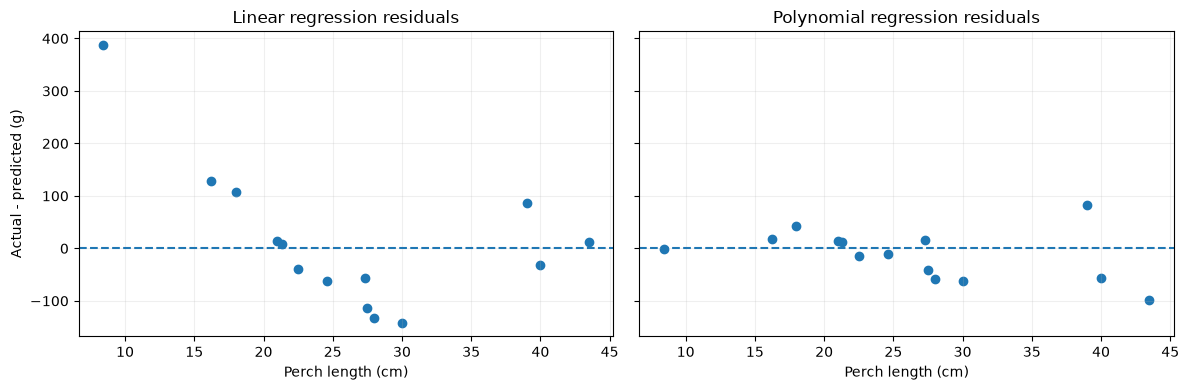

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].scatter(test_input[:, 0], linear_residual)
axes[0].axhline(0, linestyle='--')
axes[0].set_title('Linear regression residuals')
axes[0].set_ylabel('Actual - predicted (g)')

axes[1].scatter(test_input[:, 0], poly_residual)
axes[1].axhline(0, linestyle='--')
axes[1].set_title('Polynomial regression residuals')

for ax in axes:
    ax.set_xlabel('Perch length (cm)')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 4단계. 모델이 잘못 예측한 농어 살펴보기

직선 회귀에서 절댓값 잔차가 가장 큰 3마리를 확인합니다. 같은 농어에 대한 2차 다항 회귀의 잔차와 비교합니다.

In [19]:
worst_indexes = np.argsort(np.abs(linear_residual))[-3:][::-1]

print('길이 | 실제 무게 | 직선 회귀 잔차 | 다항 회귀 잔차')
for i in worst_indexes:
    print(
        f'{test_input[i, 0]:4.1f}cm | {test_target[i]:7.1f}g | '
        f'{linear_residual[i]:+12.2f}g | {poly_residual[i]:+12.2f}g'
    )

길이 | 실제 무게 | 직선 회귀 잔차 | 다항 회귀 잔차
 8.4cm |     5.9g |      +387.17g |        -0.63g
30.0cm |   320.0g |      -141.50g |       -62.21g
28.0cm |   250.0g |      -133.46g |       -57.66g


직선 회귀가 가장 크게 틀린 세 마리는 모두 2차 다항 회귀에서 오차가 줄어들었습니다. 다만 모든 농어에서 그런 것은 아닙니다. 아래 응용 실습에서 확인합니다.

### 5단계. 학생 응용 실습

`test_input`에서 가장 긴 농어 1마리를 골라(`np.argmax(test_input[:, 0])`) 두 모델의 예측값과 잔차를 직접 비교해 보세요.

**실습 핵심**: 잔차는 모델이 어느 데이터에서, 어느 방향으로, 얼마나 틀렸는지 보여줍니다. 같은 테스트 세트에서 직선 회귀보다 2차 다항 회귀의 오차가 전반적으로 작았지만, 모든 입력에서 더 정확하다는 뜻은 아닙니다.

✅ **완료 확인**: 2단계의 테스트 R²·MAE가 `0.8248 / 94.46g`, `0.9776 / 37.77g`으로 출력되고, 4단계 표의 첫 행이 8.4cm 농어(`+387.17g / -0.63g`)입니다. 응용 실습에서는 43.5cm 농어의 잔차가 직선 회귀 `+11.77g`, 다항 회귀 `-97.65g`으로 나옵니다.